# How well do GPT-2 features predict cortical fMRI responses during story listening?

| | |
| --- | --- |
| **Question** | Across the whole cortex, how well does a linear mapping from GPT-2 features predict one listener's fMRI responses to stories held out from training? |
| **Requires** | Reading the saved results: CPU only, no downloads, a few seconds (the cortical figures are pre-rendered). Rerunning the measurement: GPT-2 weights, the LeBel 2023 assembly (about 3 GB, path in `BRAINSCORE_LEBEL_PICKLE`), several GB of memory and several minutes; not run in this notebook. |
| **Lessons used** | [2. Your first benchmark](../lessons/02_your_first_benchmark.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb) |

## Background

Encoding models predict brain responses from features computed by a model of the stimulus. For natural language, features from language models predict fMRI responses in a distributed set of cortical areas during story listening. The LeBel et al. (2023) dataset ([doi:10.1038/s41597-023-02437-z](https://doi.org/10.1038/s41597-023-02437-z)) contains fMRI from participants who listened to hours of spoken stories, which makes it possible to fit a mapping on some stories and test it on others. A whole-cortex map of prediction accuracy shows where a model's features carry information about the measured responses.

## Hypothesis

Features from GPT-2 layer `h.11` predict held-out responses with a positive correlation at most cortical locations. The median correlation across all locations is small (below 0.2), because most locations are not driven by language and there is no correction for measurement noise.

## Method

**Data.** One participant (UTS03), 25 stories, 8,964 fMRI samples (TR = 2 s), 52,904 spoken words. Targets are 20,484 cortical surface locations (vertices), 10,242 per hemisphere.

**Features.** Each word is presented to GPT-2 with up to 32 preceding words of context, and the activity of layer `h.11` is recorded. That layer was selected on a different dataset (Pereira 2018), not on this one.

**Benchmark** (`LeBel2023-UTS03-encoding`):

- Word features are resampled onto the fMRI sampling grid with a Lanczos filter.
- Features delayed by 1 to 4 samples are concatenated, so the regression can model the slow blood-oxygen response.
- Each vertex is standardized within each story.
- Ridge regression is fit with five folds that hold out whole stories, so training and test samples never come from the same story.
- The score for each vertex is the Pearson correlation between predicted and measured responses on held-out stories. The reported score is the median over vertices. There is no noise-ceiling normalization.

This notebook reads the saved results of that measurement. The cell below loads the run details and the per-vertex correlations.

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

assets = Path('../assets/whole_brain')
run = json.loads((assets / 'measurements.json').read_text())
scores = np.load(assets / 'gpt2_lebel_scores.npz')
r = scores['per_vertex']   # one held-out Pearson r per cortical vertex

for key in ['model', 'layer', 'benchmark', 'subject', 'n_stories', 'n_samples', 'n_words', 'n_targets']:
    print(f'{key:10s} {run[key]}')
print(run['notes'])

model      gpt2
layer      h.11
benchmark  LeBel2023-UTS03-encoding
subject    UTS03
n_stories  25
n_samples  8964
n_words    52904
n_targets  20484
Raw held-out Pearson correlations. Five whole-story folds; registered defaults. No noise-ceiling normalization. No anatomical mask.


The next cell is the code that produces a measurement like the saved one, using the 2,000-vertex smoke variant of the benchmark. It also defines two controls. The timing-shuffled control permutes feature rows within each story, keeping the features but breaking their alignment with the brain data. The constant control gives every sample the same feature vector; its prediction does not vary, so its correlation is undefined rather than zero.

The controls override an internal feature method of the benchmark class for this diagnostic only. The cell is disabled (`RUN_LIVE = False`) because it needs the LeBel assembly and GPT-2 weights.

In [2]:
RUN_LIVE = False   # set True only with BRAINSCORE_LEBEL_PICKLE set and enough memory

if RUN_LIVE:
    import warnings
    import brainscore
    from brainscore.benchmarks.lebel2023.benchmark import LeBel2023EncodingWordLevel

    class TimingShuffled(LeBel2023EncodingWordLevel):
        """Same features and stories; word order scrambled within each story."""
        def _model_features(self, candidate, stimulus_set, assembly):
            features = super()._model_features(candidate, stimulus_set, assembly)
            stories = np.asarray(assembly['story_id'].values)
            rng = np.random.default_rng(1234)
            shuffled = features.copy()
            for story in np.unique(stories):
                rows = np.flatnonzero(stories == story)
                shuffled[rows] = features[rng.permutation(rows)]
            return shuffled

    class Constant(LeBel2023EncodingWordLevel):
        """Every sample gets an identical feature vector."""
        def _model_features(self, candidate, stimulus_set, assembly):
            return np.ones_like(super()._model_features(candidate, stimulus_set, assembly))

    subject = brainscore.load_model('gpt2')
    for label, variant in [('GPT-2', LeBel2023EncodingWordLevel),
                           ('timing-shuffled control', TimingShuffled),
                           ('constant control', Constant)]:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)   # constant control: empty correlations
            result = float(variant(identifier='null-check', max_targets=2000)(subject))
        print(f'{label:24s} median r = ' + ('undefined' if np.isnan(result) else f'{result:+.4f}'))

To regenerate the saved full-cortex measurement and figures, run from the unified repository root:

```bash
export BRAINSCORE_LEBEL_PICKLE=/path/to/assembly_lebel_uts03.pkl
RESULTCACHING_DISABLE=1 python notebooks/figure_sources/measure_whole_brain.py
python notebooks/figure_sources/render_whole_brain_figures.py
```

The [measurement script](../figure_sources/measure_whole_brain.py) runs the registered GPT-2 benchmark on all 20,484 vertices and overwrites the files in `../assets/whole_brain/`. The [renderer](../figure_sources/render_whole_brain_figures.py) redraws the figures from those values without rerunning the model.

## Results

This cell summarizes the distribution of per-vertex correlations.

In [3]:
print(f'vertices             : {r.size}')
print(f'median r             : {np.median(r):.4f}')
print(f'mean r               : {r.mean():.4f}')
print(f'fraction with r > 0  : {(r > 0).mean():.3f}')
print(f'5th / 95th percentile: {np.percentile(r, 5):.4f} / {np.percentile(r, 95):.4f}')
print(f'maximum r            : {r.max():.4f}')

vertices             : 20484
median r             : 0.1013
mean r               : 0.1134
fraction with r > 0  : 0.953
5th / 95th percentile: 0.0018 / 0.2734
maximum r            : 0.5429


The median held-out correlation across the 20,484 vertices is 0.101 and the mean is 0.113. 95.3% of vertices have a positive correlation.

The next cell shows the saved histogram of the per-vertex correlations.

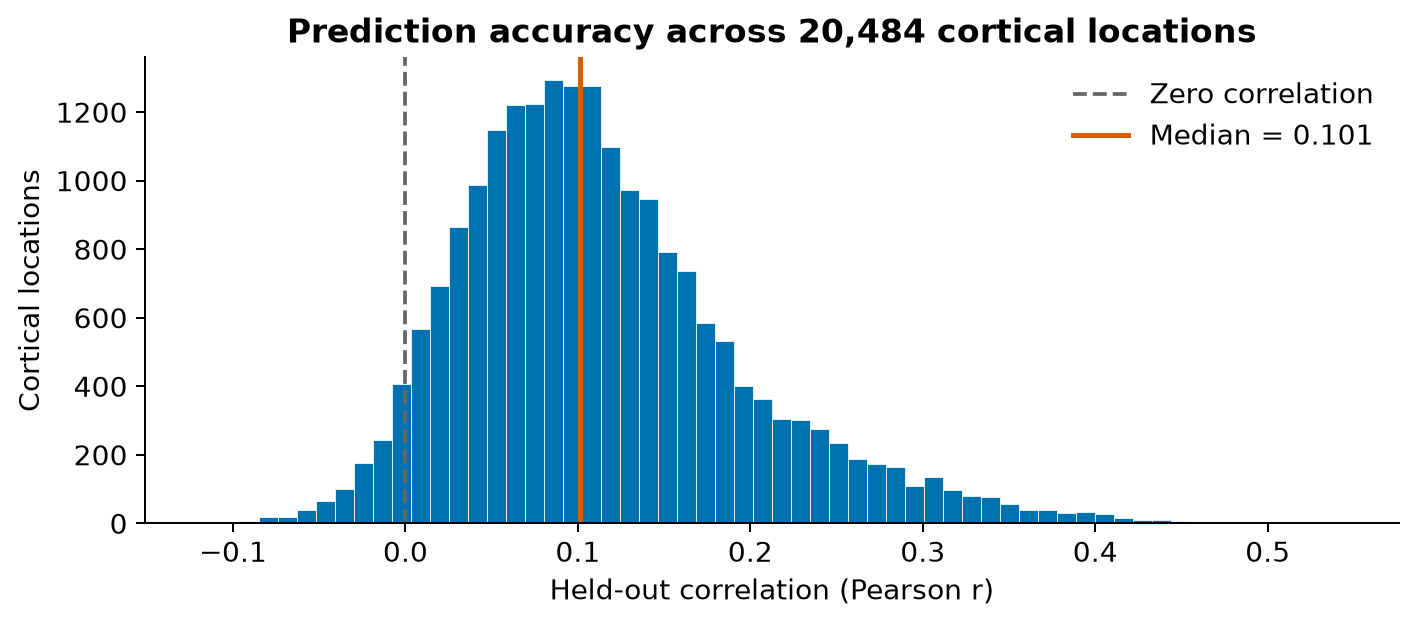

In [4]:
display(Image(filename=str(assets / 'score_distribution.png')))

The distribution is shifted above zero. The 5th percentile is 0.002, the 95th percentile is 0.273 and the highest vertex reaches 0.543.

The next cell shows the same correlations on four views of the cortical surface. Red marks positive correlation between predicted and measured responses, and blue marks negative correlation. All views share one color scale.

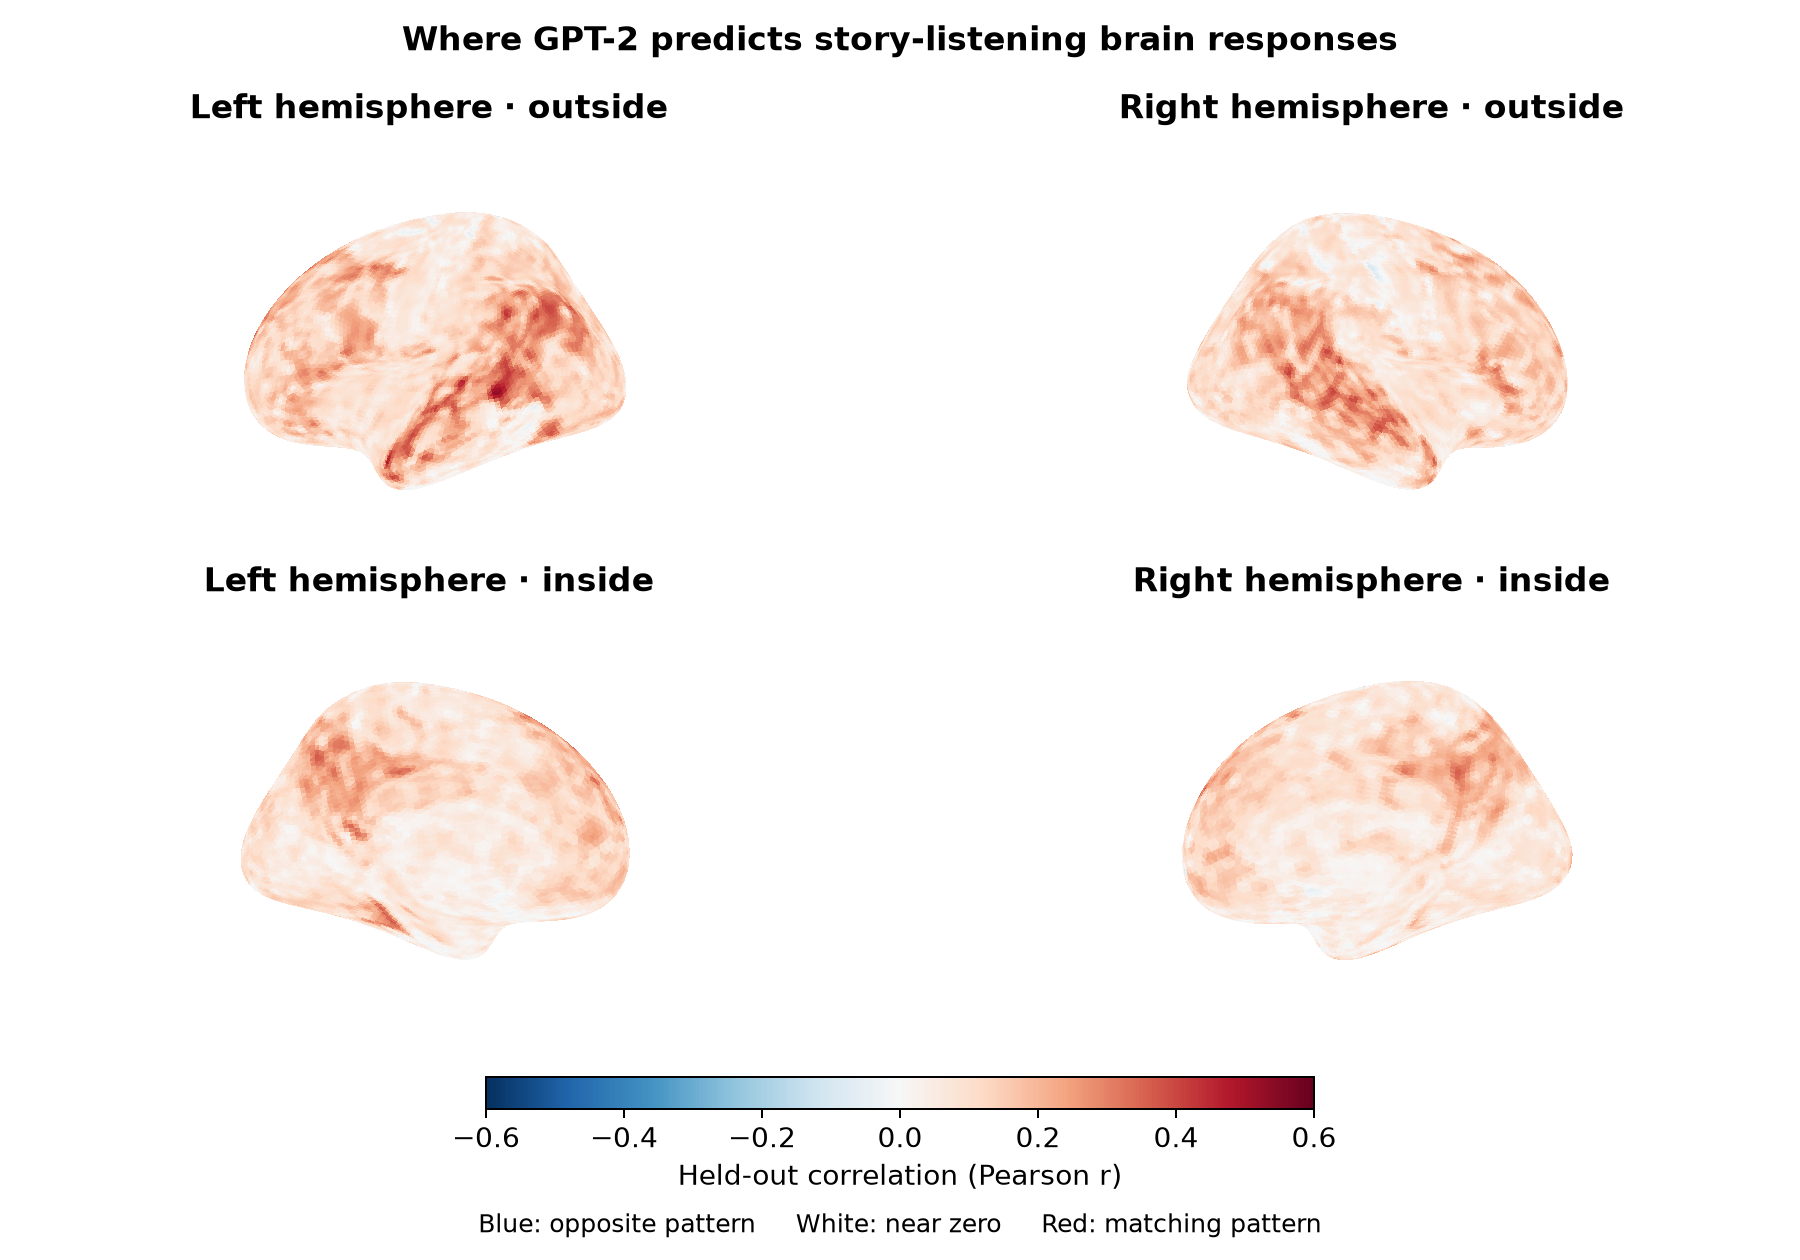

In [5]:
display(Image(filename=str(assets / 'cortical_predictions.png')))

The map shows where prediction accuracy is high on the surface. It is a map of prediction scores, not of brain activity.

## Conclusion and limits

The result is consistent with the hypothesis: GPT-2 layer `h.11` features predicted held-out story responses with a positive correlation at 95% of cortical vertices, and the median correlation was 0.10.

Limits:

- One participant. The result does not establish generalization across people.
- There is no repeat-based noise ceiling, so model error and measurement noise are not separated, and the numbers cannot be compared directly with ceiling-normalized scores.
- The timing-shuffled and constant controls were not part of the saved run. Without them, this notebook does not show how much of the score depends on the alignment between words and brain samples.
- A high correlation at a location does not establish that the location is language-selective.
- Layer `h.11` was chosen on a different dataset. Other layers were not compared here.